# PCMCI+ · LPCMCI: 레짐 없는 인과 그래프와 답지 채점

`RCBNB-MB.ipynb` 와 같은 조건에서 tigramite 의 두 방법을 2015-01-04 ~ 최신 전체에 한 번씩 적용한다.

- 데이터·변환·답지·채점: `analysis/causal_common.py` (RCBNB-MB 와 같은 함수). τ_max = 4, 유의수준 0.05, ParCorr(선형 편상관).
- 입력: `data/01_raw/causal_panel.parquet` (`uv run python analysis/causal_common.py` 로 다시 받는다). 가격과 일간 시장 변수는 **주 마지막 값**이다.
  커피 답지가 설명하는 가격은 **헤알 가격**이다(예측 파이프라인의 USD 타깃과 다르다). 커피는 CEPEA 헤알 가격 이력이 DB 에 들어온 뒤에 넣는다 — 스냅샷에 가격이 없는 원자재는 자동으로 빠진다.
- **PCMCI+**: 시차 링크와 같은 주(lag 0) 링크를 함께 찾는다.
- **LPCMCI**: 같은 주 링크와 **관측되지 않은 공통 원인(잠재 교란)** 을 허용한다. 결과는 PAG 라 끝점 표시가 세 가지다:
  `-` 꼬리(이쪽이 원인), `>` 화살촉(이쪽은 원인이 아님), `o` 미정. 예: `A o-> B` 는 "B 는 A 의 원인이 아니다, A 가 B 의 원인인지는 모른다".
- **같은 주 방향 가정**: 주간 자료에서 같은 주에 함께 움직이는 변수의 방향은 데이터로 식별되지 않는다. 그래서 가격과 변수의 같은 주 링크는
  `변수 → 가격` 으로 **가정**한다(거시·기상·수급 변수는 한 원자재 가격의 같은 주 결과가 아니다). 포지션·재고·ETF 보유량(`PFM.POS`, `FND.INV`)은
  가격에 반응할 수 있어 가정하지 않는다. 링크가 있는지는 여전히 검정으로 정한다. 표에서 가정으로 정한 방향은 `(가정)` 으로 적는다.
- 채점: `docs/commodity_weekly_drivers.xlsx` 의 주별 원인표(2023-01 ~ 2026-10). 무작위 선택의 기대 적중률(우연 기준선)을 함께 적는다.

이미 본 기간을 탐색하는 분석이다. 예측 성능 평가가 아니다.

In [1]:
import hashlib, os, pickle, time, warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from matplotlib import font_manager
from tigramite import data_processing as pp
from tigramite.independence_tests.parcorr import ParCorr
from tigramite.lpcmci import LPCMCI
from tigramite.pcmci import PCMCI

from causal_common import (ALPHA, MISSING, ROOT, SERIES, TAU, attribution, link_assumptions, load_key, make_panel,
                           score_sets, score_weeks, sinks)  # RCBNB-MB 와 같은 데이터·변환·답지·채점

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"  # 병렬 작업 프로세스에도 적용
CACHE = ROOT / "data/07_reporting/pcmci_lpcmci"  # 그래프 캐시(데이터·방법·설정의 해시). discover 를 바꾸면 이 폴더를 지운다.
CACHE.mkdir(parents=True, exist_ok=True)

METHODS = ["PCMCI+", "LPCMCI"]
LPCMCI_OPTS = {"max_p_global": 3}  # 조건 집합 크기 ≤ 3. 기본 설정(제한 없음)은 원자재 하나에 30분을 넘겨 끝나지 않았다
# LPCMCI 는 변수 수에 따라 급격히 느려진다(이전 입력 기준 10코어 맥: 커피 21개 3분, 금 24개 38분, 구리 30개는 3시간 30분 넘게 끝나지 않음).
# 지금은 금 25개·구리 32개라 둘 다 돌리지 않는다(커피만 돈다). 따로 돌려 캐시에 남기면 이 줄에서 지우기만 하면 된다.
SKIP = {("copper", "LPCMCI"): "변수 32개 — 30개일 때 3시간 30분 넘게 끝나지 않음", ("gold", "LPCMCI"): "변수 25개 — 24개일 때 38분"}

panels, sink, keys = {}, {}, {s: load_key(s) for s in SERIES}
for s in SERIES:
    panels[s], info = make_panel(s)
    sink[s] = sinks(panels[s], info)
    X = panels[s]
    print(f"{s}: T={len(X)}, 변수 {X.shape[1]}개 (가격 포함), 결측 비율={X.isna().mean().mean():.3f}, "
          f"같은 주 방향을 가정하는 변수 {sink[s].sum()}개 / 가정하지 않는 변수 {list(X.columns[1:][~sink[s][1:]].str[:40])}")

coffee: T=619, 변수 20개 (가격 포함), 결측 비율=0.090, 같은 주 방향을 가정하는 변수 17개 / 가정하지 않는 변수 ['Com_CFTC_Commitments_Of_Traders_Legacy_R', 'ecf_monthly_european_ports_green_coffee_']
copper: T=619, 변수 32개 (가격 포함), 결측 비율=0.059, 같은 주 방향을 가정하는 변수 27개 / 가정하지 않는 변수 ['Com_CFTC_Cu_noncomm_net', 'Com_LME_Cu_noncomm_fund_net', 'Com_LME_Daily_Closing_Stock_Copper_CA', 'Com_SHFE_Cu_Inv']
gold: T=619, 변수 25개 (가격 포함), 결측 비율=0.007, 같은 주 방향을 가정하는 변수 22개 / 가정하지 않는 변수 ['Com_SPDR_Gold_Shares_GLD_Tonnes_Of_Gold', 'Macro_PBOC_China_Gold_Reserves_Monthly_C']


## 1. 인과 그래프

`graph[i, j, τ]` 는 X^i(t−τ) 와 X^j(t) 사이 링크의 끝점 표시(왼쪽 = i 쪽, 오른쪽 = j 쪽). 결측 주는 `missing_flag` 로 검정에서 뺀다.

In [2]:
def discover(method, X, sink, opts):
    path = CACHE / (hashlib.md5(X.tobytes() + sink.tobytes() + repr((method, sorted(opts.items()), TAU, ALPHA)).encode()).hexdigest() + ".pkl")
    if path.exists():
        return pickle.loads(path.read_bytes())
    frame = pp.DataFrame(np.nan_to_num(X, nan=MISSING), missing_flag=MISSING)
    test = ParCorr(significance="analytic")
    t0 = time.time()
    if method == "PCMCI+":
        out = PCMCI(frame, test, verbosity=0).run_pcmciplus(tau_min=0, tau_max=TAU, pc_alpha=ALPHA, link_assumptions=link_assumptions(sink))
    else:
        out = LPCMCI(frame, test, verbosity=0).run_lpcmci(tau_min=0, tau_max=TAU, pc_alpha=ALPHA,
                                                         link_assumptions=link_assumptions(sink, pag=True), **opts)
    res = out["graph"], out["val_matrix"], time.time() - t0
    path.write_bytes(pickle.dumps(res))
    return res


jobs = [(s, m) for s in SERIES for m in METHODS if (s, m) not in SKIP]
results = dict(zip(jobs, Parallel(n_jobs=len(jobs))(
    delayed(discover)(m, panels[s].values, sink[s], LPCMCI_OPTS if m == "LPCMCI" else {}) for s, m in jobs)))
for (s, m), (g, _, sec) in results.items():
    marks = pd.Series(g[g != ""]).value_counts().to_dict()
    print(f"{s:7s} {m:6s} 계산 {sec:7.1f}초  링크 끝점 표시별 개수 {marks}")
    # 가정 확인: 가정한 변수와 가격의 같은 주 링크는 없거나, 가격 쪽이 화살촉이다(가격 → 변수 가 아니다)
    assert all(g[i, 0, 0] == "" or g[i, 0, 0][2] == ">" for i in np.flatnonzero(sink[s]))

coffee  PCMCI+ 계산     0.9초  링크 끝점 표시별 개수 {'-->': 43, 'o-o': 10, '<--': 9, 'x-x': 6}
coffee  LPCMCI 계산     4.0초  링크 끝점 표시별 개수 {'-->': 28, '<->': 22, 'o->': 4, '<-o': 3, '<--': 3}
copper  PCMCI+ 계산     8.6초  링크 끝점 표시별 개수 {'-->': 84, 'x-x': 54, '<--': 17, 'o-o': 10}
gold    PCMCI+ 계산    19.8초  링크 끝점 표시별 개수 {'-->': 82, 'x-x': 66, '<--': 13}


## 2. 가격과 이어진 링크

시차는 가격 시점 기준(−2 = 그 변수의 2주 전 값, 0 = 같은 주, +1 = 1주 뒤 값). 강도는 편상관.

| 분류 | 끝점 표시 (변수 쪽, 가격 쪽) |
| --- | --- |
| 원인 | `변수 --> 가격`. 같은 주 링크의 방향을 가정으로 정했으면 `원인 (가정)` |
| 원인 후보 | `변수 o-> 가격` (LPCMCI) |
| 결과 | `가격 --> 변수` |
| 결과 후보 | `가격 o-> 변수` (LPCMCI) |
| 잠재 교란 | `변수 <-> 가격` — 관측되지 않은 공통 원인 (LPCMCI) |
| 방향 미정 | 그 밖 (`o-o` 등) |

`답지 인용` 은 답지 전체 기간에 그 변수가 원인으로 인용된 주의 수.

In [3]:
HEAD = set("<>")


def price_links(g, val):
    """가격(0번)과 이어진 링크: (변수 번호, 시차, 변수 쪽 표시, 가격 쪽 표시, 강도)."""
    out = []
    for i, tau in zip(*np.nonzero(g[:, 0, :] != "")):  # X^i(t-tau) — 가격(t). tau=0 도 여기서 한 번만 센다
        out.append((int(i), -int(tau), g[i, 0, tau][0], g[i, 0, tau][2], val[i, 0, tau]))
    for j, tau in zip(*np.nonzero(g[0, :, 1:] != "")):  # 가격(t) — X^j(t+tau)
        out.append((int(j), int(tau) + 1, g[0, j, tau + 1][2], g[0, j, tau + 1][0], val[0, j, tau + 1]))
    return [x for x in out if x[0] != 0]  # 가격 자기 시차는 뺀다


def kind(at_var, at_price):
    if at_price == ">" and at_var == "-":
        return "원인"
    if at_price == ">" and at_var == "o":
        return "원인 후보"
    if at_var in HEAD and at_price == "-":
        return "결과"
    if at_var in HEAD and at_price == "o":
        return "결과 후보"
    if at_var in HEAD and at_price in HEAD:
        return "잠재 교란"
    return "방향 미정"


def spouses(g, links):
    """가격이 화살촉으로 들어가는 이웃 j 의, 가격 말고 j 에 화살촉으로 들어오는 다른 변수들."""
    out = set()
    for j, _, at_var, _, _ in links:
        if at_var in HEAD:
            heads = {int(k) for k, tau in zip(*np.nonzero(g[:, j, :] != "")) if g[k, j, tau][2] == ">"}
            out |= heads - {0, j}
    return out


def graph_sets(g, val, cols):
    """부모 항 {(변수, 시차 τ ≥ 0)} (가격 자기 시차 포함 — 귀속 회귀의 통제 변수) 와 채점할 변수 집합 세 가지."""
    links = price_links(g, val)
    parents = {(cols[i], -o) for i, o, a, b, _ in links if kind(a, b) in ("원인", "원인 후보")}
    adjacent = {cols[i] for i, *_ in links}
    sets = {"부모": {c for c, _ in parents}, "인접": adjacent, "MB": adjacent | {cols[k] for k in spouses(g, links)}}
    return parents | {("price", int(t) + 1) for t in np.flatnonzero(g[0, 0, 1:] != "")}, sets


def link_table(s, m):
    g, val, _ = results[s, m]
    cols = list(panels[s].columns)
    cites = keys[s].cited.explode().value_counts()
    arrow = lambda a, b: ("<" if a in HEAD else a) + "-" + (">" if b in HEAD else b)  # 변수 쪽을 왼쪽에 쓴다
    assumed = lambda i, o, a, b: " (가정)" if o == 0 and sink[s][i] and kind(a, b).startswith("원인") else ""
    rows = [(cols[i][:60], o, f"변수 {arrow(a, b)} 가격", kind(a, b) + assumed(i, o, a, b), v, int(cites.get(cols[i], 0)))
            for i, o, a, b, v in sorted(price_links(g, val), key=lambda x: (x[1], x[0]))]
    return pd.DataFrame(rows, columns=["변수", "시차(주)", "링크", "분류", "강도", "답지 인용"]).round(3)


for s, m in jobs:
    print(f"\n===== {SERIES[s]}  {m}")
    print(link_table(s, m).to_string(index=False))


===== 커피  PCMCI+
                                                          변수  시차(주)        링크      분류     강도  답지 인용
Com_CFTC_Commitments_Of_Traders_Legacy_Report_COFFEE_C_ICE_F      0 변수 o-o 가격   방향 미정  0.184      3
                                      Com_Fed_H10_EX_BRL_USD      0 변수 --> 가격 원인 (가정)  0.114     26
ecf_monthly_european_ports_green_coffee_stocks_robusta_tonne      0 변수 <-- 가격      결과 -0.160      3
Com_CFTC_Commitments_Of_Traders_Legacy_Report_COFFEE_C_ICE_F      1 변수 <-- 가격      결과  0.276      3
                    fed_h10_nominal_broad_dollar_index_daily      1 변수 <-- 가격      결과  0.097      2

===== 커피  LPCMCI
                                                          변수  시차(주)        링크    분류     강도  답지 인용
                  Weather_NOAA_CPC_Nino34_Weekly_SST_Celsius     -3 변수 <-> 가격 잠재 교란 -0.091      3
Com_CFTC_Commitments_Of_Traders_Legacy_Report_COFFEE_C_ICE_F      0 변수 <-o 가격 결과 후보  0.159      3
Com_CFTC_Commitments_Of_Traders_Legacy_Report_COFFEE_C_ICE_F      1 변수

## 3. 답지 채점

답지는 "이번 주 가격이 왜 움직였는가"를 주마다 적은 표다. 기간 전체에서 그래프 하나를 찾는 방법과 직접 비교할 수 없어 두 층으로 나눠 본다.
채점 함수는 `causal_common.py` 의 `score_sets`, `attribution`, `score_weeks`.

**(가) 변수 집합 — 기간 전체.** 시차·방향·그 주의 움직임은 보지 않는다. 답지의 간선을 맞혔다는 뜻이 아니라 "답지가 드는 변수가 집합에 들어 있는가"다.
- 부모: 가격의 원인·원인 후보(같은 주는 가정 포함). 인접: 가격과 이어진 모든 변수(방향 무시). MB: 인접 + 가격의 자식의 다른 부모(배우자).
- 포함률 = (1/|W|) Σ_w 1[C_w ∩ S ≠ ∅], W = 인용 변수가 패널에 하나 이상 있는 답지 주, C_w = 그 주의 인용 변수.
- 우연 = 같은 크기 |S| 의 무작위 변수 집합의 기대 포함률 = (1/|W|) Σ_w [1 − C(N − |C_w|, |S|) / C(N, |S|)], N = 가격 외 변수 수.

**(나) 주별 귀속 — 답지의 질문.** 가격을 그래프의 부모 항(변수, 시차)에 회귀하고, 주 w 에서 변수 i 의 기여를 Σ_τ β_iτ · x_i(w − τ) 로 둔다.
- top-k 적중률 = 그 주 |기여| 상위 k 개에 답지 인용 변수가 있는 주의 비율. 우연 = 무작위 k 개의 기대 적중률.
- `(전체 주)` = 분모가 답지 기간의 모든 주(입력에 없는 변수만 인용했거나 인용이 없는 주는 실패).
- 방향 일치 = top-3 적중 주에서 인용 변수 기여 합의 부호가 답지 등락률의 부호와 같은 비율.
- 기준 행 `전체 변수 회귀`: 변수를 고르지 않고 모든 변수의 같은 주 값에 회귀한 귀속. drivers 는 답지가 인용한 변수 목록이므로, 이 행은 "답지가 드는 변수를 전부 아는" 경우다.
- 기준 행 `|z| 크기`: 회귀도 없이 그 주에 평소보다 크게 움직인 변수 순서.

In [4]:
graphs = {(s, m): graph_sets(*results[s, m][:2], list(panels[s].columns)) for s, m in jobs}
for (s, m), why in SKIP.items():
    print(f"{s} {m}: 미계산 — {why}")
set_scores = pd.DataFrame([{"원자재": s, "방법": m, "집합": name, **score_sets(S, panels[s], keys[s])}
                           for (s, m), (_, sets) in graphs.items() for name, S in sets.items()])
set_scores["포함률 − 우연"] = set_scores["포함률"] - set_scores["우연"]
set_scores.round(3)

copper LPCMCI: 미계산 — 변수 32개 — 30개일 때 3시간 30분 넘게 끝나지 않음
gold LPCMCI: 미계산 — 변수 25개 — 24개일 때 38분


,원자재,방법,집합,집합 크기,답지 주 수,포함률,우연,포함률 − 우연
0,coffee,PCMCI+,부모,1.0,162,0.160,0.053,0.108
1,coffee,PCMCI+,인접,4.0,162,0.210,0.211,-0.001
2,coffee,PCMCI+,MB,4.0,162,0.210,0.211,-0.001
3,coffee,LPCMCI,부모,0.0,162,0.000,0.000,0.000
4,coffee,LPCMCI,인접,3.0,162,0.056,0.158,-0.102
5,coffee,LPCMCI,MB,6.0,162,0.160,0.316,-0.155
6,copper,PCMCI+,부모,4.0,175,0.263,0.129,0.134
7,copper,PCMCI+,인접,7.0,175,0.280,0.226,0.054
8,copper,PCMCI+,MB,10.0,175,0.349,0.323,0.026
9,gold,PCMCI+,부모,2.0,194,0.186,0.083,0.102


In [5]:
week_scores = pd.DataFrame(
    [{"원자재": s, "귀속": m, "부모 항": len(parents), **score_weeks(attribution(panels[s], parents), panels[s], keys[s])}
     for (s, m), (parents, _) in graphs.items()]
    + [{"원자재": s, "귀속": name, **score_weeks(c, X, keys[s]), **fix}
       for s, X in panels.items()
       for name, c, fix in [("기준: 전체 변수 회귀", attribution(X, {(v, 0) for v in X.columns[1:]}), {}),
                            ("기준: |z| 크기", X.drop(columns="price").fillna(0), {"방향 일치 (top3 적중 주)": np.nan})]]  # z 의 부호는 가격 방향이 아니다
).sort_values("원자재", kind="stable")
week_scores.round(3)

,원자재,귀속,부모 항,답지 주 수,전체 주 수,입력 밖 인용,top1,top1 우연,top1 (전체 주),top3,top3 우연,top3 (전체 주),방향 일치 (top3 적중 주)
0,coffee,PCMCI+,2.0,162,200,0,0.154,0.053,0.125,0.154,0.158,0.125,0.800
1,coffee,LPCMCI,1.0,162,200,0,0.000,0.053,0.000,0.000,0.158,0.000,NaN
4,coffee,기준: 전체 변수 회귀,NaN,162,200,0,0.117,0.053,0.095,0.210,0.158,0.170,0.765
5,coffee,기준: |z| 크기,NaN,162,200,0,0.154,0.053,0.125,0.253,0.158,0.205,NaN
2,copper,PCMCI+,4.0,175,200,13,0.154,0.032,0.135,0.263,0.097,0.230,0.717
6,copper,기준: 전체 변수 회귀,NaN,175,200,13,0.057,0.032,0.050,0.223,0.097,0.195,0.744
7,copper,기준: |z| 크기,NaN,175,200,13,0.069,0.032,0.060,0.206,0.097,0.180,NaN
3,gold,PCMCI+,2.0,194,200,1,0.139,0.042,0.135,0.186,0.125,0.180,0.917
8,gold,기준: 전체 변수 회귀,NaN,194,200,1,0.134,0.042,0.130,0.242,0.125,0.235,0.894
9,gold,기준: |z| 크기,NaN,194,200,1,0.062,0.042,0.060,0.206,0.125,0.200,NaN


## 4. 그림 — 주별 귀속 적중률과 우연 기준선

점 사이 거리가 "무작위로 k 개를 고른 것보다 얼마나 더 맞혔는가"다.

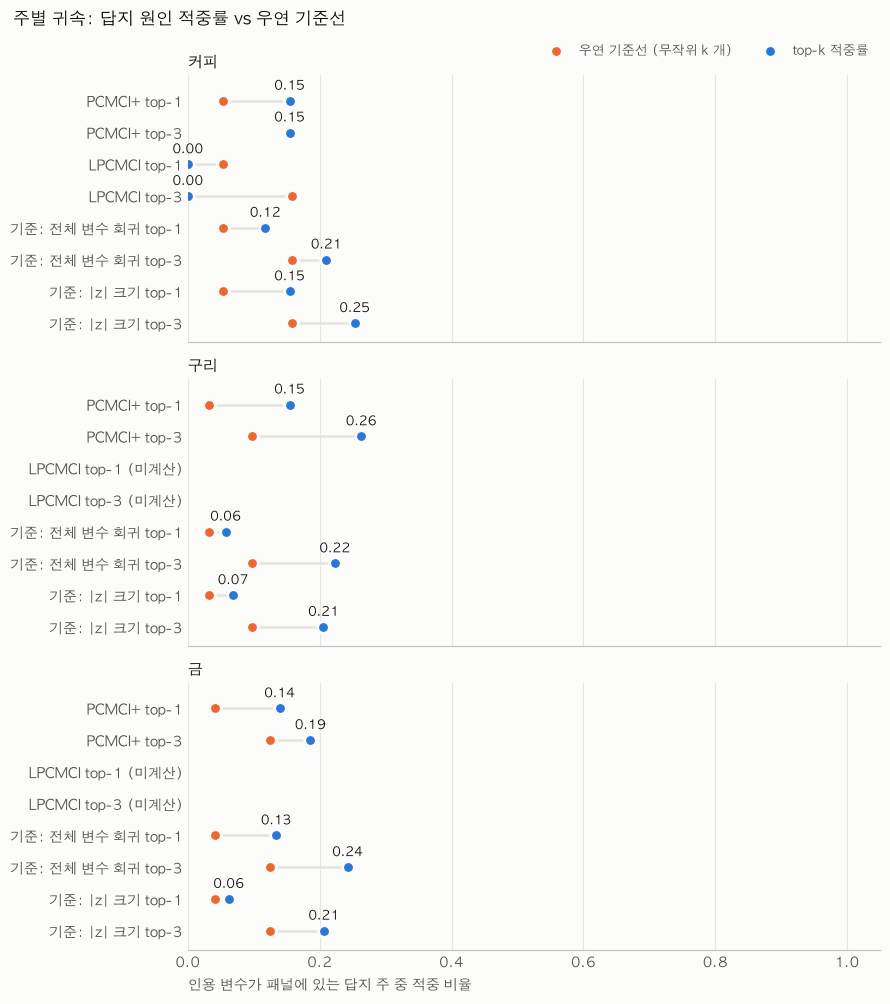

In [6]:
have = {f.name for f in font_manager.fontManager.ttflist}  # 한글 글꼴: 설치된 첫 번째 것
plt.rcParams.update({"font.family": next((f for f in ("AppleGothic", "Malgun Gothic", "NanumGothic") if f in have), "sans-serif"),
                     "axes.unicode_minus": False})
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
HIT, CHANCE = "#2a78d6", "#eb6834"

ROWS = [(m, k) for m in [*METHODS, "기준: 전체 변수 회귀", "기준: |z| 크기"] for k in (1, 3)]  # 원자재마다 같은 순서, 미계산 행도 자리를 둔다
fig, axes = plt.subplots(len(SERIES), 1, figsize=(9, 3.2 * len(SERIES) + 0.6), sharex=True, facecolor=SURFACE)
for ax, s in zip(axes, SERIES):
    d = week_scores[week_scores.원자재 == s].set_index("귀속")
    hit = np.array([d[f"top{k}"].get(m, np.nan) for m, k in ROWS])
    chance = np.array([d[f"top{k} 우연"].get(m, np.nan) for m, k in ROWS])
    y = np.arange(len(ROWS))[::-1]
    ax.hlines(y, chance, hit, color=GRID, lw=2, zorder=1)
    ax.scatter(chance, y, s=70, color=CHANCE, edgecolor=SURFACE, linewidth=2, zorder=2, label="우연 기준선 (무작위 k 개)")
    ax.scatter(hit, y, s=70, color=HIT, edgecolor=SURFACE, linewidth=2, zorder=3, label="top-k 적중률")
    for yy, h in zip(y, hit):
        if not np.isnan(h):
            ax.annotate(f"{h:.2f}", (h, yy), xytext=(0, 8), textcoords="offset points", ha="center", color=INK, fontsize=9)
    ax.set_yticks(y, [f"{m} top-{k}" + (" (미계산)" if np.isnan(h) else "") for (m, k), h in zip(ROWS, hit)])
    ax.set_title(SERIES[s], loc="left", color=INK, fontsize=11)
    ax.set_xlim(0, 1.05)
    ax.set_ylim(-0.6, len(ROWS) - 0.2)
    ax.set_facecolor(SURFACE)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, length=0)
axes[0].legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1.02), ncol=2, labelcolor=MUTED, fontsize=9)
axes[-1].set_xlabel("인용 변수가 패널에 있는 답지 주 중 적중 비율", color=MUTED, loc="left")
fig.suptitle("주별 귀속: 답지 원인 적중률 vs 우연 기준선", x=0.02, ha="left", color=INK)
fig.tight_layout()
plt.show()

## 5. 결과 요약 (2026-11-08 까지의 스냅샷, 2026-11-13 수정 답지)

커피 가격은 CEPEA 헤알 가격이다(2026-11-13 에 과거 이력을 DB 에 넣었다). 주간 등락률이 답지의 `등락률(%)` 과 200주 모두 일치한다.

**주별 귀속** — top-k 적중률 / 우연 기준선. 분모는 인용 변수가 패널에 있는 답지 주(커피 162, 구리 175, 금 194).

| 원자재 | 귀속 | 가격의 부모 변수 | top-1 | top-3 | 방향 일치 |
| --- | --- | --- | --- | --- | --- |
| 커피 | PCMCI+ | 1개 (헤알 환율) | **0.15 / 0.05** | 0.15 / 0.16 | 0.80 |
| 커피 | LPCMCI | 0개 | 0.00 / 0.05 | 0.00 / 0.16 | — |
| 커피 | 기준: 전체 변수 회귀 | (19개 전부) | 0.12 / 0.05 | 0.21 / 0.16 | 0.76 |
| 커피 | 기준: \|z\| 크기 | — | 0.15 / 0.05 | 0.25 / 0.16 | — |
| 구리 | PCMCI+ | 4개 (달러, VIX, LME 스프레드, 중국 산업생산) | **0.15 / 0.03** | **0.26 / 0.10** | 0.72 |
| 구리 | 기준: 전체 변수 회귀 | (31개 전부) | 0.06 / 0.03 | 0.22 / 0.10 | 0.74 |
| 구리 | 기준: \|z\| 크기 | — | 0.07 / 0.03 | 0.21 / 0.10 | — |
| 금 | PCMCI+ | 2개 (달러, 10년물 금리) | **0.14 / 0.04** | 0.19 / 0.13 | 0.92 |
| 금 | 기준: 전체 변수 회귀 | (24개 전부) | 0.13 / 0.04 | 0.24 / 0.13 | 0.89 |
| 금 | 기준: \|z\| 크기 | — | 0.06 / 0.04 | 0.21 / 0.13 | — |

**변수 집합(기간 전체)** — PCMCI+ 부모 집합의 포함률 / 우연: 커피 0.16 / 0.05, 구리 0.26 / 0.13, 금 0.19 / 0.08.
PCMCI+ 의 인접·MB 집합은 우연과 구분되지 않는다(차이 −0.00 ~ +0.05).

읽는 법
- **답지 최다 인용 변수가 이제 가격의 원인으로 잡힌다.** 달러 지수(구리 36주·금 29주 인용)와 헤알 환율(커피 26주)이 같은 주 원인이다(편상관 −0.25, −0.43, +0.11).
  이전 판에서 이 변수들이 "가격 → 변수" 로 나온 것은 일간 변수를 주 평균으로, 가격을 주 마지막 값으로 짝지어 생긴 가짜 시차였다.
  **방향 자체는 찾은 것이 아니라 가정이다** — 데이터가 말하는 것은 "같은 주에 다른 변수로 설명되지 않는 연관이 있다"까지다.
- **PCMCI+ 부모 집합은 세 원자재 모두 우연의 2~3배다**(이전 판의 원인 집합은 세 원자재 모두 우연보다 낮았다). top-1 적중률은 우연의 3~5배다.
- **그래도 답지 주의 15~26% 만 맞힌다. 이 상한은 그래프 탐색이 아니라 답지와 주간 자료의 관계에서 온다.**
  답지가 드는 변수를 전부 넣은 회귀(`전체 변수 회귀`)도 top-3 가 0.21 ~ 0.24 다. 변수 1~4개만 고른 PCMCI+ 가 구리에서는 이미 그 수준이고,
  커피·금은 부모 변수가 1~2개라 top-3 가 그보다 낮다.
  답지는 그 주의 뉴스가 든 이유를 적은 것이라, 인용된 변수가 그 주에 유난히 크게 움직였거나 가격 변동의 큰 몫을 설명한다는 보장이 없다.
- 맞힌 주에서는 방향도 대체로 맞는다(0.72 ~ 0.92).
- **커피의 최다 인용 변수인 강수(미나스 47주 등 60건)는 4주 평년 대비 편차로 넣어도 가격과 유의한 링크가 없다.**
- LPCMCI(커피)는 가격의 원인을 하나도 남기지 않았다. 헤알 환율 링크가 없고, 남은 링크는 잠재 교란·결과로 분류됐다.
- 금의 최다 인용 변수인 2년물 금리(39주)는 부모로 남지 않았다(남은 부모는 달러와 10년물 금리).

한계
- LPCMCI 는 조건 집합 크기 ≤ 3 으로 제한했고, 금·구리는 계산 시간 때문에 돌리지 않았다.
- 답지가 인용한 변수 중 DB 주간 뷰에 없는 것(구리 13건, 금 1건)은 입력에 없다. `(전체 주)` 열이 이 주들과 인용이 없는 주를 실패로 센 값이다.
- 귀속 회귀는 결측을 0(평균)으로 두고 전체 기간에 한 번 적합한다. 계수는 이미 본 기간 전체에서 나온 것이다.
- 계단형 변수끼리의 검정은 유효 표본이 발표 횟수라 p 값이 낙관적이다.
- 같은 주 방향 가정은 포지션·재고·ETF 보유량에는 걸지 않았다. 이 변수들은 대부분 "가격 → 변수"(결과)로 나온다.
- 헤알 가격은 정의상 달러 가격 × 환율이라, 헤알 환율 → 헤알 가격 링크에는 환산 효과가 섞여 있다.


## 리더보드 내보내기

위 표와 같은 귀속·채점을 `analysis/notebook_board.py` 형식으로 쓴다. 올리기: `uv run python tools/log_causal_leaderboard.py --path <출력 폴더>`. 이 노트북의 평가 조건(`protocol`)은 `in_sample_full` 라 다른 조건의 run 과 같은 순위에 넣지 않는다.


In [7]:
from notebook_board import export

rows = []
for s, X in panels.items():
    cands = {m: attribution(X, graphs[s, m][0]) for m in METHODS if (s, m) in graphs}
    cands["기준: 전체 변수 회귀"] = attribution(X, {(v, 0) for v in X.columns[1:]})
    cands["기준: |z| 크기"] = X.drop(columns="price").fillna(0)
    for m, c in cands.items():
        rows.append(dict(name=m, phase="all", series=s, contrib=c, X=X, key=keys[s], parent="" if m in ("PCMCI+", "기준: |z| 크기") else "PCMCI+",
                         axis="baseline" if m.startswith("기준") else "model",
                         override={"방향 일치 (top3 적중 주)": np.nan} if m == "기준: |z| 크기" else {}))  # z 의 부호는 가격 방향이 아니다
    rows += [dict(name=m, phase="all", series=s, X=X, key=keys[s], parent="PCMCI+", axis="model", status="skipped")
             for m in METHODS if (s, m) in SKIP]
export("pcmci_lpcmci", "PCMCI-LPCMCI.ipynb", rows, "in_sample_full", specs={"LPCMCI": dict(LPCMCI_OPTS, skipped={f"{s}": why for (s, m), why in SKIP.items()})})


exported 12 rows, 1 comparisons → /Users/sonet/Desktop/01_riotinto/data/07_reporting/causal_notebooks/pcmci_lpcmci/40ff00da7360900aa1b2


PosixPath('/Users/sonet/Desktop/01_riotinto/data/07_reporting/causal_notebooks/pcmci_lpcmci/40ff00da7360900aa1b2')